# M5 Demand Forecasting → Inventory Decisions
## Notebook 04 — From forecast to ordering decision (inventory simulation)

**Goal:** turn forecasts into **how much to stock**, then replay the 12 backtest weeks to measure what that decision costs: **sales lost to empty shelves** vs. **inventory held**. We compare a forecast-driven policy with a naive policy that a store could run with a spreadsheet.

**Input:** `data/processed/forecasts_backtest.parquet` (Notebook 03) · **Output:** headline numbers, figures, and the dashboard data in `app/data/`

**Runtime:** ~1 minute.

### How it works (plain English)

**The store's routine.** Every product-store gets **two deliveries a week**: Monday's covers Mon–Wed (3 days), Thursday's covers Thu–Sun (4 days, including the weekend peak from Notebook 02). At each delivery the shelf is topped up to a **target level**:

> **target = expected demand until the next delivery + safety stock**
> **safety stock = z × σ × √(days covered)**

- **σ** = how much daily sales jumped around in the 28 days before the forecast origin (standard deviation).
- **z** = the service dial. Higher z → more safety stock → fewer stockouts but more inventory. z = 1.65 is the classic "95% service" setting.
- Demand the shelf can't cover is **lost** (the customer leaves). Leftover stock carries over to the next delivery.

**Two policies, one difference.** Same rule, same σ, same z, same information date. Only *expected demand* changes:

| Policy | Expected demand until the next delivery |
|---|---|
| **Naive** | 28-day moving average × days covered (every day treated the same) |
| **Forecast** | Sum of the LightGBM mean forecasts for those days (knows weekends, SNAP, prices, events) |

So any difference in the results comes from **the forecast alone**.

**Keeping it honest.**
- Forecasts for each 4-week block were made on the block's first Monday (Notebook 03). Deliveries late in a block use forecasts made up to 3½ weeks earlier.
- Demand = actual sales. Products with any *likely unavailable* day in the 12 weeks are left out, because their true demand is unknown.
- We **compare at equal average inventory**. Holding more stock always reduces stockouts, so the fair question is *"for the same inventory, who loses fewer sales?"* We trace each policy's full trade-off curve by sweeping z, then compare the curves.

## Setup

In [1]:
import os, sys, gc, json, time, warnings
warnings.filterwarnings('ignore')

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_DIR = '/content/drive/MyDrive/m5-inventory'
else:
    PROJECT_DIR = os.path.abspath('..')          # running from the repo's notebooks/ folder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

PROCESSED_DIR = os.path.join(PROJECT_DIR, 'data', 'processed')
FIG_DIR       = os.path.join(PROJECT_DIR, 'reports', 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Same chart style as Notebook 02
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#c3c2b7',
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': '#e6e5e0', 'grid.linewidth': 0.8,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'lines.linewidth': 2, 'legend.frameon': False,
})
BLUE, ORANGE, GRAY, INK = '#2a78d6', '#eb6834', '#b5b4ad', '#52514e'

def save_fig(fig, name):
    path = os.path.join(FIG_DIR, f'{name}.png')
    fig.savefig(path, dpi=150, bbox_inches='tight')
    print('Saved:', os.path.relpath(path, PROJECT_DIR))

from scipy.stats import norm

fc = pd.read_parquet(os.path.join(PROCESSED_DIR, 'forecasts_backtest.parquet'))
fc = fc.sort_values(['store_id', 'item_id', 'date']).reset_index(drop=True)

# Keep products with full 12-week history and no likely-unavailable day (true demand known)
g = fc.groupby(['item_id', 'store_id'], observed=True)
fc['n_days'] = g['date'].transform('size')
fc['any_unavail'] = g['unavailable'].transform('any')
sim_df = fc[(fc['n_days'] == 84) & ~fc['any_unavail']].copy()

N = sim_df.groupby(['item_id', 'store_id'], observed=True).ngroups
D = 84
n_all = fc.groupby(['item_id', 'store_id'], observed=True).ngroups
print(f"Simulating {N:,} of {n_all:,} product-stores over {D} days "
      f"({sim_df['date'].min().date()} → {sim_df['date'].max().date()}); "
      f"{n_all - N:,} excluded for a likely-unavailable day")

Simulating 3,566 of 4,311 product-stores over 84 days (2016-02-29 → 2016-05-22); 745 excluded for a likely-unavailable day


## Step 1 — Arrays: one row per product-store, one column per day

In [2]:
def grid(col):
    return np.nan_to_num(sim_df[col].to_numpy(dtype='float64').reshape(N, D))

demand    = grid('sales')        # what customers bought (our demand)
price     = grid('sell_price')
fc_mean   = grid('mean')         # LightGBM expected demand per day
ma_28     = grid('o_mean_28')    # naive: 28-day average before the origin (flat across the block)
sigma_28  = grid('o_std_28')     # daily std over the 28 days before the origin (used by BOTH policies)
p50, p90  = grid('p50'), grid('p90')

dates = sim_df['date'].iloc[:D].dt.normalize().to_numpy()
assert pd.Timestamp(dates[0]).day_name() == 'Monday'
print(f"Average demand per product per day: {demand.mean():.2f} units | total units: {demand.sum():,.0f}")

Average demand per product per day: 1.81 units | total units: 543,409


## Step 2 — The policy and the simulator

`delivery_blocks` lists which days each delivery covers. `targets` turns daily expected demand and σ into an order-up-to level for every delivery and every z at once. `simulate` replays the 84 days for **all products and all z values simultaneously** (numpy arrays), so the whole sweep takes seconds.

In [3]:
DELIVERY_DAYS = [0, 3]                      # Monday, Thursday
Z_GRID = np.round(np.arange(-1.0, 4.0001, 0.05), 2)

def delivery_blocks(delivery_days):
    """(first_day, last_day+1) covered by each delivery across the 12 weeks."""
    blocks = []
    for w in range(D // 7):
        for j, d0 in enumerate(delivery_days):
            d1 = delivery_days[j + 1] if j + 1 < len(delivery_days) else 7
            blocks.append((7 * w + d0, 7 * w + d1))
    return blocks

def targets(mu_daily, sigma_daily, blocks, zs, sigma_mode='sqrt_days'):
    """Order-up-to level per (z, product, delivery): expected demand + z * spread."""
    mu = np.stack([mu_daily[:, a:b].sum(1) for a, b in blocks], axis=1)
    if sigma_mode == 'sqrt_days':        # sigma * sqrt(days): days treated as independent
        sg = np.stack([sigma_daily[:, a] * np.sqrt(b - a) for a, b in blocks], axis=1)
    else:                                # 'sum_sq': combine a different sigma for each day
        sg = np.stack([np.sqrt((sigma_daily[:, a:b] ** 2).sum(1)) for a, b in blocks], axis=1)
    return np.ceil(np.maximum(mu[None] + np.asarray(zs)[:, None, None] * sg[None], 0))

def simulate(target, blocks, zs, days=slice(0, D)):
    """Replay the days: deliver up to target, sell what we can, lose the rest, carry leftovers."""
    Z = len(zs)
    stock = np.zeros((Z, N)); lost = np.zeros((Z, N)); lost_val = np.zeros((Z, N))
    onhand = np.zeros((Z, N)); onhand_val = np.zeros((Z, N))
    starts = {a: k for k, (a, b) in enumerate(blocks)}
    for t in range(days.start, days.stop):
        if t in starts:
            stock = np.maximum(stock, target[:, :, starts[t]])        # top up (never remove stock)
        sold = np.minimum(stock, demand[None, :, t])
        miss = demand[None, :, t] - sold
        stock -= sold
        lost += miss; lost_val += miss * price[None, :, t]
        onhand += stock; onhand_val += stock * price[None, :, t]
    n_days = days.stop - days.start
    dem = demand[:, days]
    return pd.DataFrame({
        'z': zs,
        'lost_rate': lost.sum(1) / dem.sum(),                         # share of demand not served
        'avg_onhand_units': onhand.sum(1) / (N * n_days),             # per product, end of day
        'avg_onhand_value': onhand_val.sum(1) / n_days,               # $ across all products, avg day
        'lost_value_per_day': lost_val.sum(1) / n_days,               # $ of sales lost per day
        'lost_value_share': lost_val.sum(1) / (dem * price[:, days]).sum(),
    })

blocks = delivery_blocks(DELIVERY_DAYS)
naive = simulate(targets(ma_28,   sigma_28, blocks, Z_GRID), blocks, Z_GRID)
model = simulate(targets(fc_mean, sigma_28, blocks, Z_GRID), blocks, Z_GRID)
print(f"{len(blocks)} deliveries per product · {len(Z_GRID)} service settings · both policies simulated")

24 deliveries per product · 101 service settings · both policies simulated


## Step 3 — Headline: same inventory, fewer lost sales?

Reference point: the **naive policy at the classic 95% setting (z = 1.65)**. We read off its average inventory, then find the forecast policy's lost-sales rate **at exactly that inventory** on its own curve (interpolation along the z sweep). And the reverse: how much inventory the forecast policy needs to match the naive lost-sales rate.

In [4]:
def at_z(curve, z):
    return {c: float(np.interp(z, curve['z'], curve[c])) for c in curve.columns if c != 'z'}

def lost_at_inventory(curve, inv, inv_col='avg_onhand_units', lost_col='lost_rate'):
    return float(np.interp(inv, curve[inv_col], curve[lost_col]))

def inventory_at_lost(curve, lost, inv_col='avg_onhand_units', lost_col='lost_rate'):
    c = curve.sort_values(lost_col)
    return float(np.interp(lost, c[lost_col], c[inv_col]))

Z_REF = 1.645
ref = at_z(naive, Z_REF)
m_lost = lost_at_inventory(model, ref['avg_onhand_units'])
m_inv = inventory_at_lost(model, ref['lost_rate'])
headline = {
    'naive_lost_rate': ref['lost_rate'],
    'model_lost_rate_equal_inventory': m_lost,
    'lost_reduction_equal_inventory': 1 - m_lost / ref['lost_rate'],
    'inventory_saving_equal_lost': 1 - m_inv / ref['avg_onhand_units'],
    'naive_avg_onhand_units': ref['avg_onhand_units'],
}
# Same comparison in dollars (inventory value vs. lost sales value)
mv = lost_at_inventory(model, ref['avg_onhand_value'], 'avg_onhand_value', 'lost_value_share')
headline['lost_value_reduction_equal_inventory_value'] = 1 - mv / ref['lost_value_share']

print(f"Naive policy @ 95% setting : loses {ref['lost_rate']:.2%} of demand, holds {ref['avg_onhand_units']:.2f} units/product")
print(f"Forecast policy, same stock: loses {m_lost:.2%} of demand  →  {headline['lost_reduction_equal_inventory']:.1%} fewer lost sales")
print(f"Forecast policy, same lost-sales rate: needs {headline['inventory_saving_equal_lost']:.1%} less inventory")
print(f"In dollars (equal inventory value): {headline['lost_value_reduction_equal_inventory_value']:.1%} less lost sales value")

Naive policy @ 95% setting : loses 4.42% of demand, holds 7.70 units/product
Forecast policy, same stock: loses 3.94% of demand  →  10.7% fewer lost sales
Forecast policy, same lost-sales rate: needs 4.6% less inventory
In dollars (equal inventory value): 12.0% less lost sales value


Saved: reports/figures/04_01_tradeoff_curve.png


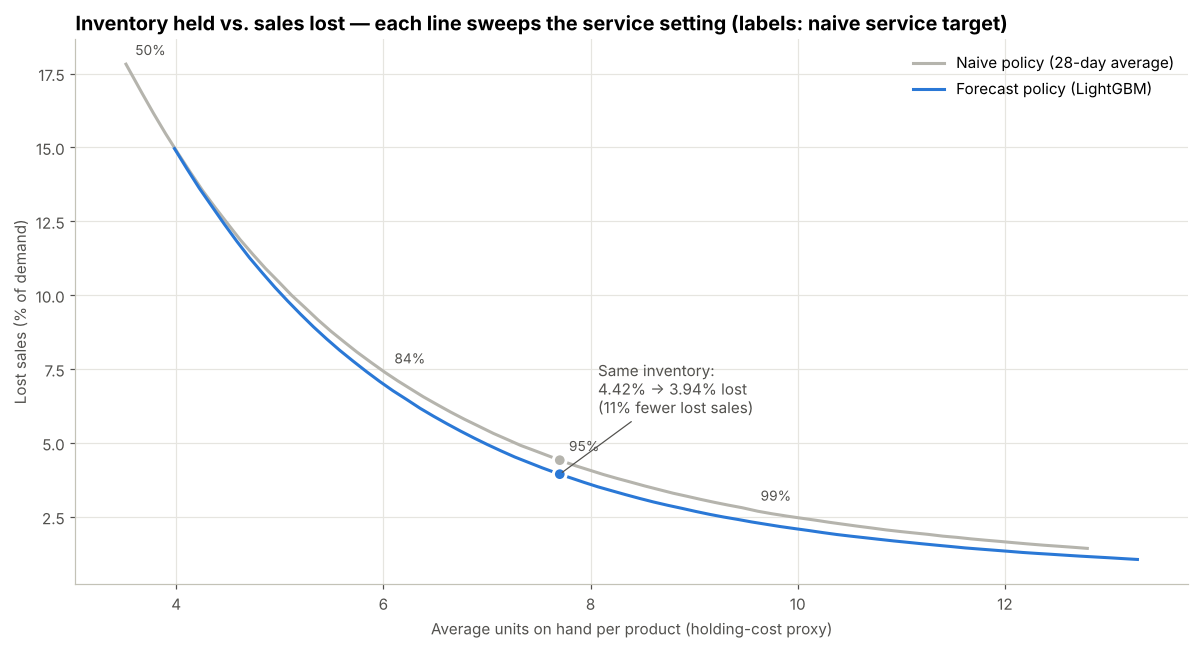

In [5]:
fig, ax = plt.subplots(figsize=(11, 6))
show = lambda c: c[c['z'].between(0, 3.5)]
for curve, name, color in [(naive, 'Naive policy (28-day average)', GRAY), (model, 'Forecast policy (LightGBM)', BLUE)]:
    c = show(curve)
    ax.plot(c['avg_onhand_units'], c['lost_rate'] * 100, color=color, label=name)
ax.scatter([ref['avg_onhand_units']] * 2, [ref['lost_rate'] * 100, m_lost * 100], color=[GRAY, BLUE],
           s=70, zorder=3, edgecolor='white', linewidth=2)
ax.annotate(f"Same inventory:\n{ref['lost_rate']:.2%} → {m_lost:.2%} lost\n({headline['lost_reduction_equal_inventory']:.0%} fewer lost sales)",
            xy=(ref['avg_onhand_units'], m_lost * 100), xytext=(25, 40), textcoords='offset points', color=INK,
            arrowprops=dict(arrowstyle='-', color=INK, lw=0.8))
for zlab in [0, 1.0, 1.645, 2.33]:
    p = at_z(naive, zlab)
    ax.annotate(f'{norm.cdf(zlab):.0%}', (p['avg_onhand_units'], p['lost_rate'] * 100),
                xytext=(6, 6), textcoords='offset points', color=INK, fontsize=9)
ax.set_title('Inventory held vs. sales lost — each line sweeps the service setting (labels: naive service target)')
ax.set_xlabel('Average units on hand per product (holding-cost proxy)')
ax.set_ylabel('Lost sales (% of demand)')
ax.legend(loc='upper right')
fig.tight_layout(); save_fig(fig, '04_01_tradeoff_curve'); plt.show()

## Step 4 — Does it hold up?

A single number can be luck. We check the gain **in each 4-week fold separately** and **across service settings** from 80% to 98%.

In [6]:
rows = []
for fold in range(3):
    days = slice(28 * fold, 28 * (fold + 1))
    fb = [b for b in blocks if days.start <= b[0] < days.stop]
    nv = simulate(targets(ma_28, sigma_28, fb, Z_GRID), fb, Z_GRID, days)
    md = simulate(targets(fc_mean, sigma_28, fb, Z_GRID), fb, Z_GRID, days)
    r = at_z(nv, Z_REF); l = lost_at_inventory(md, r['avg_onhand_units'])
    rows.append({'check': f'Fold {fold + 1} ({pd.Timestamp(dates[days.start]).date()})', 'naive lost': r['lost_rate'],
                 'forecast lost (same stock)': l, 'fewer lost sales': 1 - l / r['lost_rate']})
for z in [0.84, 1.28, 1.645, 2.05]:
    r = at_z(naive, z); l = lost_at_inventory(model, r['avg_onhand_units'])
    rows.append({'check': f'Service setting {norm.cdf(z):.0%}', 'naive lost': r['lost_rate'],
                 'forecast lost (same stock)': l, 'fewer lost sales': 1 - l / r['lost_rate']})
robust = pd.DataFrame(rows).set_index('check')
print(robust.to_string(formatters={c: '{:.2%}'.format for c in robust.columns[:2]} | {'fewer lost sales': '{:+.1%}'.format}))

                    naive lost forecast lost (same stock) fewer lost sales
check                                                                     
Fold 1 (2016-02-29)      4.96%                      4.42%           +11.0%
Fold 2 (2016-03-28)      3.43%                      3.09%           +10.2%
Fold 3 (2016-04-25)      5.11%                      4.58%           +10.5%
Service setting 80%      8.49%                      8.08%            +4.8%
Service setting 90%      5.90%                      5.43%            +7.9%
Service setting 95%      4.42%                      3.94%           +10.7%
Service setting 98%      3.30%                      2.85%           +13.6%


## Step 5 — What else did we try? (ablations)

Being transparent about alternatives makes the result more credible:
- **Weekly deliveries** instead of twice-weekly. With one delivery a week, day-of-week knowledge matters less, so the forecast's edge should shrink.
- **Safety stock from the quantile forecasts** instead of the 28-day σ. The daily spread is taken as (P90 − P50)/1.28 or (P90 − mean)/1.28 (1.28 = z for 90% under a normal curve), combined across the days covered.

In [7]:
def gain(mu, sg, dd=DELIVERY_DAYS, sigma_mode='sqrt_days'):
    b = delivery_blocks(dd)
    nv = simulate(targets(ma_28, sigma_28, b, Z_GRID), b, Z_GRID)
    md = simulate(targets(mu, sg, b, Z_GRID, sigma_mode), b, Z_GRID)
    r = at_z(nv, Z_REF)
    return 1 - lost_at_inventory(md, r['avg_onhand_units']) / r['lost_rate']

abl = pd.Series({
    'Main: twice-weekly, forecast mean + 28-day σ': headline['lost_reduction_equal_inventory'],
    'Weekly deliveries (Mon only)': gain(fc_mean, sigma_28, dd=[0]),
    'Quantile σ = (P90 − P50) / 1.28': gain(fc_mean, np.maximum(p90 - p50, 0) / 1.2816, sigma_mode='sum_sq'),
    'Quantile σ = (P90 − mean) / 1.28': gain(fc_mean, np.maximum(p90 - fc_mean, 0) / 1.2816, sigma_mode='sum_sq'),
}, name='fewer lost sales at equal inventory vs naive @95%')
print(abl.to_frame().to_string(formatters={abl.name: '{:+.1%}'.format}))

                                             fewer lost sales at equal inventory vs naive @95%
Main: twice-weekly, forecast mean + 28-day σ                                            +10.7%
Weekly deliveries (Mon only)                                                            +10.6%
Quantile σ = (P90 − P50) / 1.28                                                          +6.0%
Quantile σ = (P90 − mean) / 1.28                                                         +9.5%


## Step 6 — In dollars

The same equal-inventory comparison, measured in money: average **inventory value** on the shelf vs. **sales value lost** to empty shelves. Then a rough annual figure for these 3 stores, with an assumed **30% gross margin**.

In [8]:
MARGIN = 0.30
v_ref = at_z(naive, Z_REF)
lost_model_val = lost_at_inventory(model, v_ref['avg_onhand_value'], 'avg_onhand_value', 'lost_value_per_day')
recovered_day = v_ref['lost_value_per_day'] - lost_model_val
headline.update({
    'avg_inventory_value': v_ref['avg_onhand_value'],
    'naive_lost_value_per_day': v_ref['lost_value_per_day'],
    'model_lost_value_per_day_equal_inventory': lost_model_val,
    'sales_recovered_per_year': recovered_day * 365,
    'margin_recovered_per_year': recovered_day * 365 * MARGIN,
})
print(f"Average inventory value on the shelf (both policies): ${v_ref['avg_onhand_value']:,.0f}")
print(f"Sales lost to empty shelves: naive ${v_ref['lost_value_per_day']:,.0f}/day  vs  forecast ${lost_model_val:,.0f}/day")
print(f"→ about ${recovered_day * 365:,.0f} of sales per year recovered with the same inventory "
      f"(≈ ${recovered_day * 365 * MARGIN:,.0f} gross margin at {MARGIN:.0%}), "
      f"across {N:,} product-stores in 3 stores")

Average inventory value on the shelf (both policies): $77,151
Sales lost to empty shelves: naive $692/day  vs  forecast $609/day
→ about $30,267 of sales per year recovered with the same inventory (≈ $9,080 gross margin at 30%), across 3,566 product-stores in 3 stores


## Step 7 — Export data for the Streamlit dashboard

In [9]:
APP_DIR = os.path.join(PROJECT_DIR, 'app', 'data')
os.makedirs(APP_DIR, exist_ok=True)

trade = pd.concat([naive.assign(policy='Naive policy'), model.assign(policy='Forecast policy')])
trade = trade[trade['z'].between(0, 3.5)]
trade.to_csv(os.path.join(APP_DIR, 'tradeoff.csv'), index=False)

# A browsable sample of products: 20 best sellers + 20 random others
vol = sim_df.groupby(['item_id', 'store_id'], observed=True)['sales'].sum().sort_values(ascending=False).reset_index()
pick = pd.concat([vol.head(20), vol.iloc[20:].sample(20, random_state=42)])
sample = sim_df.merge(pick[['item_id', 'store_id']], on=['item_id', 'store_id'])
sample = sample[['item_id', 'store_id', 'date', 'sales', 'mean', 'p50', 'p90']].copy()
for c in ['item_id', 'store_id']:
    sample[c] = sample[c].astype(str)
sample['label'] = sample['item_id'] + ' · ' + sample['store_id']
sample.to_parquet(os.path.join(APP_DIR, 'series_sample.parquet'), index=False)

ev = fc[~fc['unavailable']]
rmse = lambda c: float(np.sqrt(((ev['sales'] - ev[c]) ** 2).mean()))
mae = lambda c: float((ev['sales'] - ev[c]).abs().mean())
summary = {
    'n_series': int(N),
    'test_start': str(pd.Timestamp(dates[0]).date()), 'test_end': str(pd.Timestamp(dates[-1]).date()),
    'headline': headline,
    'forecast_metrics': {'rmse_mean': rmse('mean'), 'rmse_ma28': rmse('o_mean_28'), 'rmse_snaive': rmse('snaive_28'),
                         'mae_p50': mae('p50'), 'mae_ma28': mae('o_mean_28'), 'mae_snaive': mae('snaive_28'),
                         'p90_coverage': float((ev['sales'] <= ev['p90']).mean())},
    'method_md': (
        "- **Data:** Walmart M5, 3 Texas stores, FOODS category. Backtest Feb 29 – May 22, 2016 (3 folds × 28 days).\n"
        "- **Forecasts:** one global LightGBM model (Tweedie loss) for expected daily demand, plus P50/P90 quantile models. "
        "Features are measured at each Monday forecast origin (no leakage).\n"
        "- **Policy:** deliveries Monday (covers Mon–Wed) and Thursday (Thu–Sun). Order up to expected demand until the next "
        "delivery + z × σ × √days, where σ is the daily sales std over the 28 days before the origin.\n"
        "- **Naive policy:** identical rule, but expected demand = 28-day moving average × days.\n"
        "- **Simulation:** actual sales as demand, lost sales when the shelf is empty, leftovers carry over, no spoilage. "
        "Products with likely-unavailable days in the test period are excluded (true demand unknown).\n"
        "- **Costs:** holding cost = inventory value × annual rate / 365; lost margin = lost sales value × margin."),
}
with open(os.path.join(APP_DIR, 'summary.json'), 'w') as f:
    json.dump(summary, f, indent=2)
print('App data written:', sorted(os.listdir(APP_DIR)))
print(json.dumps(headline, indent=2))

App data written: ['series_sample.parquet', 'summary.json', 'tradeoff.csv']
{
  "naive_lost_rate": 0.044170597100894535,
  "model_lost_rate_equal_inventory": 0.03942888813926258,
  "lost_reduction_equal_inventory": 0.10734989501728798,
  "inventory_saving_equal_lost": 0.04637220783636509,
  "naive_avg_onhand_units": 7.702803260956654,
  "lost_value_reduction_equal_inventory_value": 0.11980411122301149,
  "avg_inventory_value": 77151.1899188364,
  "naive_lost_value_per_day": 692.146677978656,
  "model_lost_value_per_day_equal_inventory": 609.2246603874632,
  "sales_recovered_per_year": 30266.53642078537,
  "margin_recovered_per_year": 9079.960926235612
}


## Summary — Notebook 04

**Setup:** 3,566 product-stores (3 Texas stores, FOODS) · 12 weeks (Feb 29 – May 22, 2016) · deliveries Monday + Thursday · lost sales when the shelf is empty.

| At the naive policy's 95%-setting inventory (7.70 units/product) | Naive | Forecast policy |
|---|---|---|
| Lost sales (% of demand) | 4.42% | **3.94%** |
| Sales value lost per day | $692 | **$609** |

- **10.7% fewer lost sales at equal inventory**, or **4.6% less inventory** for the same lost-sales rate. In dollars: **12.0% less lost sales value** at equal inventory value (≈ $30K of sales a year for these 3 stores' FOODS shelves).
- **Robust:** +10.2% to +11.0% in each 4-week fold; the edge grows with the service target (+4.8% at 80% → +13.6% at 98%).
- **Same rule, same σ, same z, same information date.** Only the expected-demand forecast differs, so the gain is attributable to the forecast.
- **Ablations:** weekly deliveries give a similar gain (+10.6%). Safety stock from the quantile forecasts did *worse* (+6.0% / +9.5%) than the simple 28-day σ: daily quantiles on intermittent data are coarse (the P50 is often 0). So the quantiles are used to show per-product risk, not to set safety stock.

**Limitations (worth saying in an interview):** demand = observed sales (themselves limited by Walmart's real stock); orders arrive instantly at each delivery (no extra lead time beyond forecasts made up to 3½ weeks ahead); no spoilage, case packs, or shelf-space limits; products with a likely stockout during the test window were excluded; 3 stores, FOODS only.